## <font color='black'> FlyFinder version 1.0 (1-panel images - Panasonic Camera )</font>
This notebook provides the sequence of instructions and commands for training a random forest classifer <br>
used during segmentation. It also give instructions and the commands of the whole process of segmentation.
<br><br>
If the model has been trained for a specific study setup, there will be no need to retrain, the user can <br>
immediately proceed to section 2 for first segmentation.

<u> Used camera model:</u><br>
Panosonic DC-ZS200<br>
<u>Settings</u>:<br> 
Aspect-ration 1:1<br>
Picture size: 3648 X 3648 pxl<br>
Filter settings: monochrome<br>
Use a 10-second selt timer for three pictures<br>


### Section 1: Training the classifier

- [1.1. Setting up initial parameters](#l1)
   
- [1.2. Training the random forest classifier](#l2)

### Section 2: Segmentation of images
   
- [2.1. Performing the first segmentation](#l3)

- [2.2. Manual editing the failed images ](#l4)

- [2.3. Performing the second segmentation](#l5)

- [2.4. Creating the table of fly coordinates ](#l6)

- [2.5. Calculating the nearest neighbors distances](#l7)
 

### <font color='blue'><b>Section 1: Training the classifier</b></font>

### <font color='blue'> 1.0. Importing FlyFinder Functions </font>

In [1]:
from FF_utils import *

<a name="l1"></a>
### <font color='blue'> 1.1. Setting up initial parameters </font>

<b>  - The parameters for drawing:</b>

In [2]:
# Defining the colors
blue=(0,0,255); red=(255,0,0); magenta=(255,0,255); 

# Setting the line, point and figure size
pen=5;  point=15; figSize=5

<b>  - Cropping the sides, masking the background and visualization (1-panel images): </b><br>
The <b>cropLeft</b>, <b>cropRight</b>, <b>cropTop</b> and <b>cropBottom</b> are used to crop the left, right,<br> 
top and  bottom sides the input images in case it is necessary.<br>
The <b>bottomMargin</b> and <b>topGap</b> parameters are used to demarcate the triangle such that the area inside the <br>
lines will be used while the area outside will be ignored. Different values can be tired to determine the best<br>
fit for a particular imaging setup. The demarcated pictures can be viewed in the next command

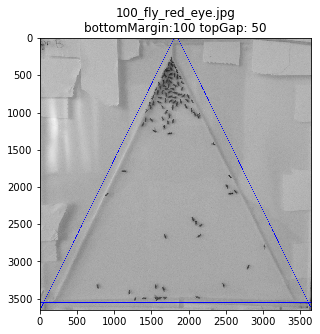

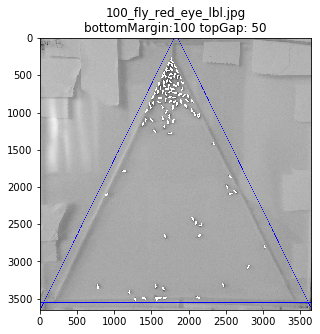

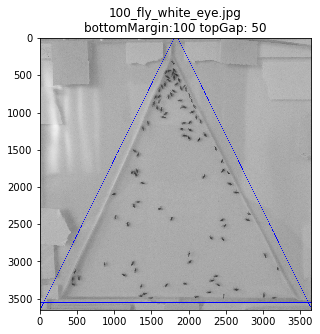

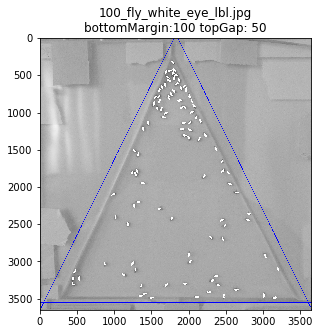

In [3]:
#Cropping the input image if necessary (pxl)
cropLeft4=0
cropRight4=0
cropTop4=0
cropBottom4=0

# Applying the mask:
# bottomMargin : correspond to the marging applied to the bottom of the image
# topgap : correspond to the distance between the two sides-triangle lines (at the top of the picture)   

bottomMargin4=100
topGap4=50

## Visualization
imagPath_="/varidata/research/projects/mnp/tool.dev/FlyFinder_v1.0/train_1p/"
viewImageMargins1Panel(imagPath=imagPath_, bottomMargin=bottomMargin4, topGap=topGap4, cropLeft=cropLeft4, cropRight=cropRight4, cropTop=cropTop4, cropBottom=cropBottom4,  marginCol=blue, figSize=figSize, pen_=pen) 

<a name="l2"></a>
### <font color='blue'> 1.2. Training the random forest classifier </font>

After getting the best values of <b>bottomMargin</b> and <b>topGap</b> that best demarcate the <br>
triangle (i.e bottomMargin=60 topGap=10), they will be used to traini either a 1 or 4Panel-based random forest classifier.<br>

We can first see the script parameters like this:

In [6]:
! python FlyFinder_train.py --help


-* FlyFinder_v1.0 *-

usage: FlyFinder_train.py [-h] --modelName MODELNAME --plateType PLATETYPE
                          --nGaussianFilters NGAUSSIANFILTERS --nMedianFilters
                          NMEDIANFILTERS --nEstimators NESTIMATORS
                          --bottomMargin BOTTOMMARGIN --topGap TOPGAP
                          --cropLeft CROPLEFT --cropRight CROPRIGHT --cropTop
                          CROPTOP --cropBottom CROPBOTTOM --inPath INPATH

optional arguments:
  -h, --help            show this help message and exit
  --modelName MODELNAME
                        the name you want to give to your random forest
                        classifier.
  --plateType PLATETYPE
                        the 1 panel plate '1panel' or 4 panel plate '4panel'.
  --nGaussianFilters NGAUSSIANFILTERS
                        the number of gaussian filters. Default=40.
  --nMedianFilters NMEDIANFILTERS
                        the number of median filters. Default=40.
  --nEstimators N

<b>- Check if there are trained models:</b>

In [7]:
! python FlyFinder_train.py models


-* FlyFinder_v1.0 *-

Available trained random forest classifiers:

M4Panel_GF40_MF10_Es30_mar100_topG50_RFC




<b>- Viewing the directory of images used for segmentation: </b><br>
Note: the labelled image for training must have '_lbl' added to its name right before the '.jpg' file extension.

In [8]:
!ls /varidata/research/projects/mnp/tool.dev/FlyFinder_v1.0/train_1p/

100_fly_red_eye.jpg	 100_fly_white_eye.jpg
100_fly_red_eye_lbl.jpg  100_fly_white_eye_lbl.jpg


<b>Executing the script that trains the random forest classifer (4-panel images):</b>

<u>Training settings:</u><br>
plateType = 4Panel (this can be changed to 1Panel if dealing with 1-panel/triangle images)<br>
Number of gaussian filters (nGaussianFilters=40) <br>
Median filters (nMedianFilters=10) <br>
Number of trees (nEstimators=30) <br>
bottomMargin = 100 <br> 
topGap = 50 <br>
cropLeft=0 <br>
cropRight=0 <br>
cropTop=0<br>
cropBottom=0<br>

In [13]:

! python FlyFinder_train.py --modelName "M1Panel_GF40_MF10_Es30_mar100_topG50_RFC" \
                            --plateType 1Panel \
                            --nGaussianFilters=40 \
                            --nMedianFilters=10 \
                            --nEstimators 30 \
                            --bottomMargin 100 \
                            --topGap 50 \
                            --cropLeft 0 \
                            --cropRight 0 \
                            --cropTop 0 \
                            --cropBottom 0 \
                            --inPath /varidata/research/projects/mnp/tool.dev/FlyFinder_v1.0/train_4p/


-* FlyFinder_v1.0 *-


Training a random forest classifier for image segmentation ( 1Panel images) 
----------------------------------------------------------------------------------

Original images:['4panels_400flies.jpg']
Labeled images: ['4panels_400flies_lbl.jpg']
Training set size: 1 files

4panels_400flies.jpg	4panels_400flies_lbl.jpg
 Generating features -- please wait, it might take some minutes ...
(6383524, 51)


 
Dimensions after removing dupliate rows:
 (4992335, 51)
Trainning the RandomForestClassifier, number of estimators =  30 


 Confusion matrix:
[[489645   1561]
 [  1589   6439]]

Accuracy = 0.9936903335910615

Feature_importance:
--------------------
<class 'pandas.core.series.Series'>
 Gaussian_1       0.114819
Median_5          0.107181
Median_7          0.074714
Median_3          0.069957
Median_1          0.066700
 Gaussian_2       0.056192
Median_2          0.047481
Median_4          0.046997
Median_9          0.042752
Median_6          0.035553
Median_8    

<b>- The resulting model has:</b><br>
Accuracy = 0.993
Training duration =  16.49 min 

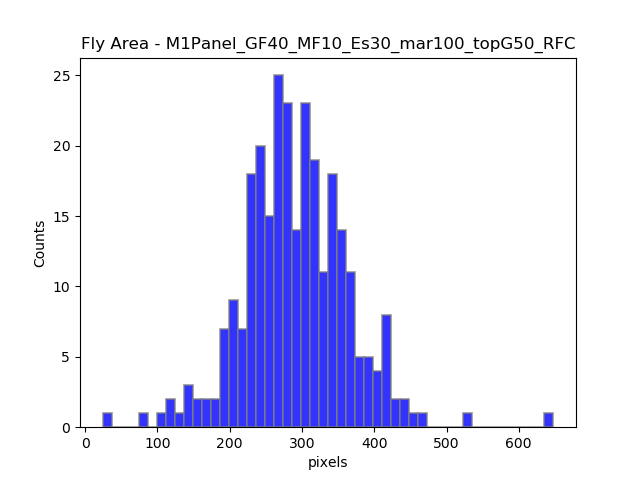

In [14]:
## Viewing the flyArea density plot

from IPython.display import Image
Image(filename="/varidata/research/projects/mnp/tool.dev/FlyFinder_v1.0/RFC_model/M1Panel_GF40_MF10_Es30_mar100_topG50_RFC_flyArea.png", width=400, height=400)

### <font color='blue'><b>Section 2: Segmentation of images</b></font>

### <font color='blue'> 2.0. Importing FlyFinder functions </font>

In [1]:
from FF_utils import *

<a name="l3"></a>
### <font color='blue'> 2.1. Performing the first segmentation </font>


 Viewing the script parameters of the script that perfroms the first segmentation:

In [2]:
! python FlyFinder_first_segmentation.py --help


-* FlyFinder_v1.0 *-

usage: FlyFinder_first_segmentation.py [-h] --modelName MODELNAME --plateType
                                       PLATETYPE --nGaussianFilters
                                       NGAUSSIANFILTERS --nMedianFilters
                                       NMEDIANFILTERS --bottomMargin
                                       BOTTOMMARGIN --topGap TOPGAP --cropLeft
                                       CROPLEFT --cropRight CROPRIGHT
                                       --cropTop CROPTOP --cropBottom
                                       CROPBOTTOM --maxArea MAXAREA --minArea
                                       MINAREA --numFlies NUMFLIES --inPath
                                       INPATH

optional arguments:
  -h, --help            show this help message and exit
  --modelName MODELNAME
                        the name of the random forest classifier to use.
  --plateType PLATETYPE
                        the 1 panel plate '1panel' or 4 panel plate '4pa

<b> - Setting up initial parameters (4-panel images) </b><br>
Here we use the same image parameter as previous

In [3]:
## Initial parameters for drawing

blue=(0,0,255); red=(255,0,0); magenta=(255,0,255); 
pen=10                                               # if pen=5 or less the bottom lines might not be visible 
point=15
figSize=5

<b>- Visualization</b><br>
This verifies that the bottomMargin and topGap work for all images. Adjust if needed.

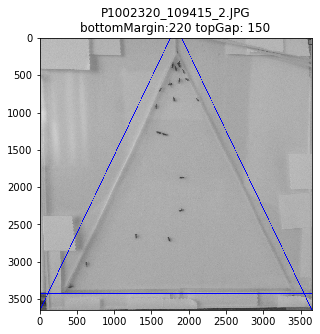

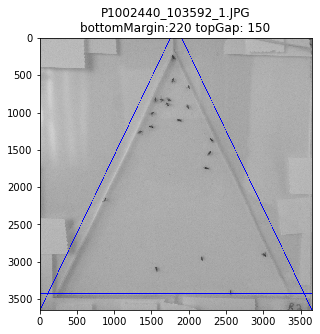

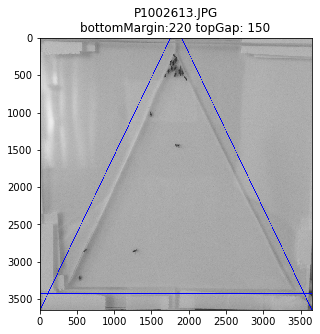

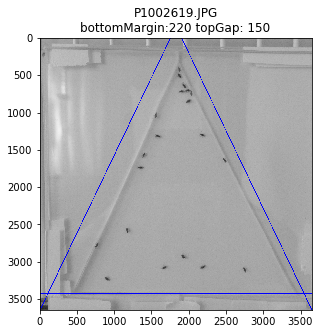

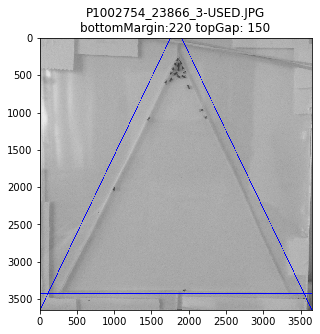

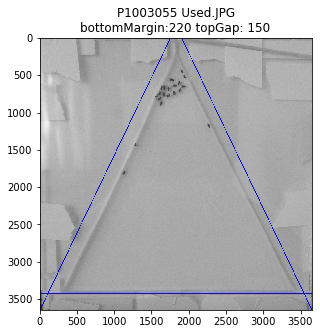

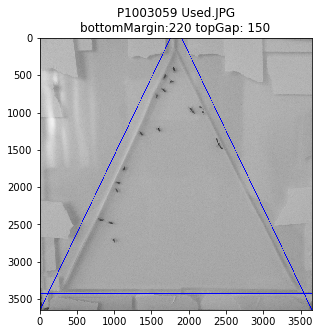

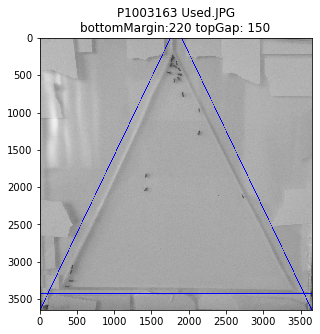

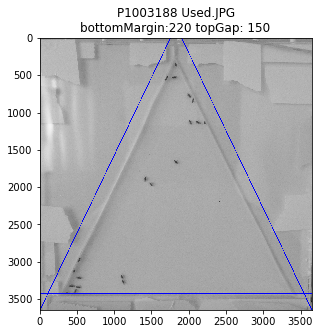

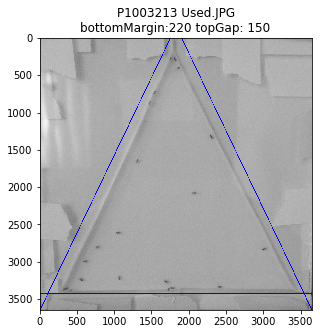

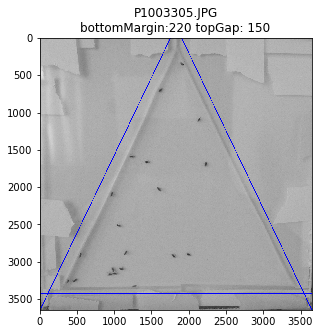

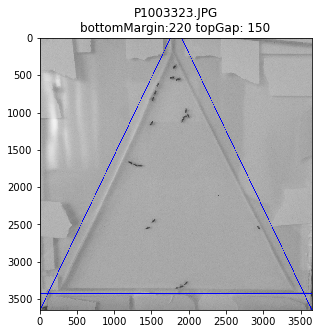

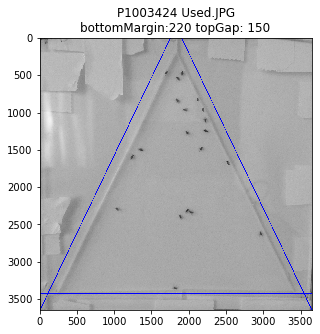

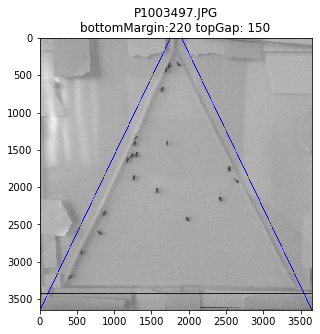

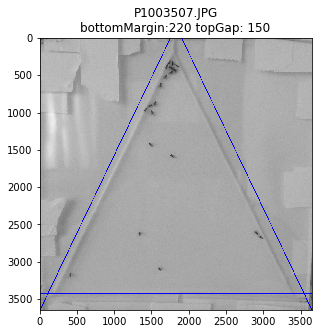

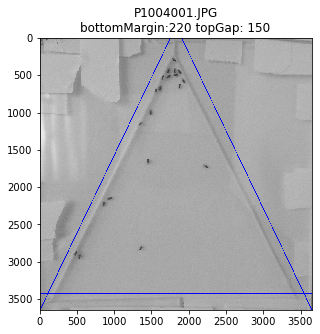

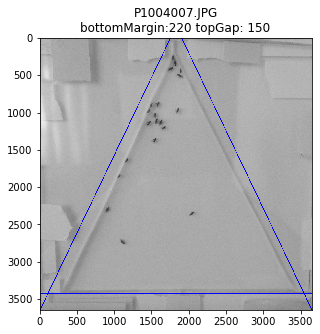

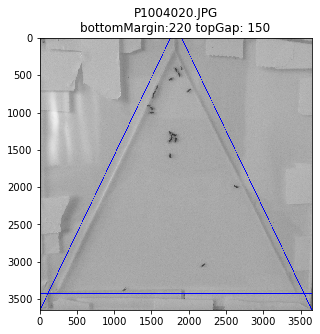

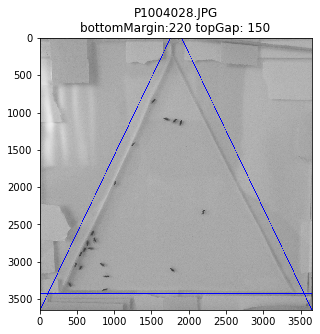

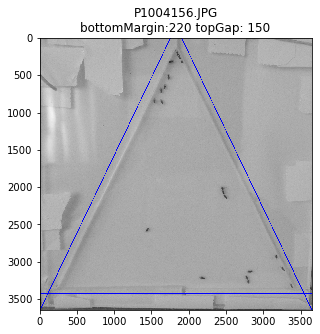

In [4]:
#Cropping the input image if necessary (pxl)
cropLeft4=0
cropRight4=0
cropTop4=0
cropBottom4=0

# Applying the mask:
# bottomMargin : correspond to the marging applied to the bottom of the image
# topgap : correspond to the distance between the two sides-triangle lines (at the top of the picture)   

bottomMargin4=220
topGap4=150

## Visualization
imagPath_="/varidata/research/projects/mnp/tool.dev/FlyFinder_v1.0/test_1p/"
viewImageMargins1Panel(imagPath=imagPath_, bottomMargin=bottomMargin4, topGap=topGap4, cropLeft=cropLeft4, cropRight=cropRight4, cropTop=cropTop4, cropBottom=cropBottom4,  marginCol=blue, figSize=figSize, pen_=pen) 


<b>- Checking the names of trained models: both train and first segmentation scripts can help checking available models:</b><br>
Both <i>FlyFinder_train.py</i> and <i> FlyFinder_first_segmentation.py</i> functions can show trained/available models if passe the 'models' parameter.

In [6]:
! python FlyFinder_train.py models


-* FlyFinder_v1.0 *-

Available trained random forest classifiers:

M1Panel_GF40_MF10_Es30_mar100_topG50_RFC
M4Panel_GF40_MF10_Es30_mar100_topG50_RFC




In [7]:
! python FlyFinder_first_segmentation.py models


-* FlyFinder_v1.0 *-

Avalable random forest classifiers:

M1Panel_GF40_MF10_Es30_mar100_topG50_RFC
M4Panel_GF40_MF10_Es30_mar100_topG50_RFC




<b>- Checking the content of the input directory:</b><br>
The directory must contain the images in jpeg format. The file name should end with '.jpg' or '.JPG'

In [9]:
!ls /varidata/research/projects/mnp/tool.dev/FlyFinder_v1.0/test_1p/

 P1002320_109415_2.JPG	    'P1003055 Used.JPG'   P1003497.JPG
 P1002432_103499_2.JPG	    'P1003059 Used.JPG'   P1003507.JPG
 P1002440_103592_1.JPG	    'P1003163 Used.JPG'   P1004001.JPG
'P1002467 Used.JPG'	    'P1003188 Used.JPG'   P1004007.JPG
'P1002587 Used.JPG'	    'P1003213 Used.JPG'   P1004020.JPG
 P1002613.JPG		     P1003305.JPG	  P1004028.JPG
 P1002619.JPG		     P1003323.JPG	  P1004156.JPG
 P1002754_23866_3-USED.JPG   P1003399.JPG
'P1003049 Used.JPG'	    'P1003424 Used.JPG'


<b>- Running the first segmentation script:</b></br>
The script can be run in <u>parallel</u> using the <b>mpiexec</b> command and by specifying the number <br>
of cores (processors) using the <b>-n</b> parameter. The script can also be run in serial using simply the following command:<br>
<i>python FlyFinder_first_segmentation.py {add command line arguments} </i>
<br><br>
Example of runing the script in parallel:

In [10]:
from FF_utils import *

In [11]:
! mpiexec -n 25  python FlyFinder_first_segmentation.py --modelName M1Panel_GF40_MF10_Es30_mar100_topG50_RFC \
                                                        --plateType 1Panel \
                                                        --minArea 120 \
                                                        --maxArea 550 \
                                                        --nGaussianFilters 40 \
                                                        --nMedianFilters 10 \
                                                        --bottomMargin 220 \
                                                        --topGap 150 \
                                                        --cropLeft 0 \
                                                        --cropRight 0 \
                                                        --cropTop 0 \
                                                        --cropBottom 0 \
                                                        --numFlies 20 \
                                                        --inPath /varidata/research/projects/mnp/tool.dev/FlyFinder_v1.0/test_1p/


-* FlyFinder_v1.0 *-




*--- Running FlyFinder Random Forest-based segmantation : core n. 00 ---*

-----------------------------------------------------------------------------------------------

Started time: 2021-08-19 09:09:51.775127



Active path : /varidata/research/projects/mnp/tool.dev/FlyFinder_v1.0/test_1p/

Settings :
Namespace(bottomMargin=220, cropBottom=0, cropLeft=0, cropRight=0, cropTop=0, inPath='/varidata/research/projects/mnp/tool.dev/FlyFinder_v1.0/test_1p/', maxArea=550, minArea=120, modelName='M1Panel_GF40_MF10_Es30_mar100_topG50_RFC', nGaussianFilters=40, nMedianFilters=10, numFlies=20, plateType='1Panel', topGap=150)

Loading the RFC model. Please wait ... 

  Model loaded successfully: /varidata/research/projects/mnp/tool.dev/FlyFinder_v1.0/RFC_model/M1Panel_GF40_MF10_Es30_mar100_topG50_RFC.pkl


  Number of images : 25

['P1002613.JPG', 'P1002320_109415_2.JPG', 'P1004156.JPG', 'P1003424 Used.JPG', 'P1003497.JPG', 'P1003163 Used.JPG', 'P1003213 Used.JPG', 'P1

##### <a name="l4"></a>
### <font color='blue'> 2.2. Manual editing the failed images</font>


The output after segmentation contains two directories:<br>
<b>FlyFinder_v1.0/test_1p/out</b> for well segmented images and <b>FlyFinder_v1.0/test_1p/outf</b> for failed images.<br> 
For a quick review of all figures it is recommended to open and check the <b>out.pdf</b> and <b>outf.pdf</b> located in <b>out</b> and <b>outf</b> directories respectively. <br> 

The user must first check for any potential failed images in the out directory and move both the .csv and .jpg files to the <br>
outf directory. All .jpg images in the outf directory must then be manually edited. Editing involves ensuring all flies are <br>
correctly identified by a white 10px by 10px box and background noise (incorrectly labeled white boxes) deleted/blackened. Image<br>
editing can be performed using Fiji or any photo editing software.


In [13]:
!ls /varidata/research/projects/mnp/tool.dev/FlyFinder_v1.0/test_1p/outf

 outf.pdf			      p1002754_23866_3-used_flies_21.jpg
 p1002432_103499_2_flies_22.csv      'p1003163 used_flies_21.csv'
 p1002432_103499_2_flies_22.jpg      'p1003163 used_flies_21.jpg'
'p1002587 used_flies_21.csv'	      p1003497_flies_21.csv
'p1002587 used_flies_21.jpg'	      p1003497_flies_21.jpg
 p1002613_flies_22.csv		      p1003507_flies_21.csv
 p1002613_flies_22.jpg		      p1003507_flies_21.jpg
 p1002754_23866_3-used_flies_21.csv


<a name="l5"></a>
### <font color='blue'> 2.3. Performing the second segmentation </font>


Similar to the other scripts, the FlyFinder_second_segmentation.py script can be run in parallel or in serial.<br>
Below is an example of how to run in parallel.

In [20]:
! mpiexec -n 5  python FlyFinder_second_segmentation.py  --inPath /varidata/research/projects/mnp/tool.dev/FlyFinder_v1.0/test_1p/outf


-* FlyFinder_v1.0 *-


Performing segmantation for image where flies are marked with 10x10 pxl white points (squares)
----------------------------------------------------------------------------------------
Started time: 2021-08-19 09:52:00.632082



Active path : /varidata/research/projects/mnp/tool.dev/FlyFinder_v1.0/test_1p/outf/


Number of images 8



p1003497_flies_21.jpg

p1003507_flies_21.jpg
Time elabsed: 0.07 min / 4.15 seconds 


done
Duration: 0.07 min / 4.19 seconds



*---  FlyFinder post-processing segmentation completed successfully! ---*


End time: 2021-08-19 09:52:04.819629




Viewing the output after post-procesing. Directory FlyFinderV2.0/test_4p/outf/out_ps

In [19]:
! ls /varidata/research/projects/mnp/tool.dev/FlyFinder_v1.0/test_1p/outf/out_ps

 out_ps.pdf
 p1002432_103499_2_flies_22_flies_20_ps.csv
 p1002432_103499_2_flies_22_flies_20_ps.jpg
'p1002587 used_flies_21_flies_20_ps.csv'
'p1002587 used_flies_21_flies_20_ps.jpg'
 p1002613_flies_22_flies_20_ps.csv
 p1002613_flies_22_flies_20_ps.jpg
 p1002754_23866_3-used_flies_21_flies_21_ps.csv
 p1002754_23866_3-used_flies_21_flies_21_ps.jpg
'p1003163 used_flies_21-1_flies_20_ps.csv'
'p1003163 used_flies_21-1_flies_20_ps.jpg'
'p1003163 used_flies_21_flies_21_ps.csv'
'p1003163 used_flies_21_flies_21_ps.jpg'
 p1003497_flies_21_flies_20_ps.csv
 p1003497_flies_21_flies_20_ps.jpg
 p1003507_flies_21_flies_20_ps.csv
 p1003507_flies_21_flies_20_ps.jpg


<a name="l6"></a>
### <font color='blue'> 2.4. Creating the table of fly coordinates</font>

A python script is used to compile one main table that combines all tables of  xy-coordinates of fly location from each image

In [21]:
! python FlyFinder_maketable.py --inPath  /varidata/research/projects/mnp/tool.dev/FlyFinder_v1.0/test_1p/


* RFC segmantation : Number of tables = 18

p1002320_109415_2_flies_20.csv
p1002440_103592_1_flies_20.csv
p1002467 used_flies_20.csv
p1002619_flies_20.csv
p1003049 used_flies_20.csv
p1003055 used_flies_20.csv
p1003059 used_flies_20.csv
p1003188 used_flies_20.csv
p1003213 used_flies_20.csv
p1003305_flies_20.csv
p1003323_flies_20.csv
p1003399_flies_20.csv
p1003424 used_flies_20.csv
p1004001_flies_20.csv
p1004007_flies_20.csv
p1004020_flies_20.csv
p1004028_flies_20.csv
p1004156_flies_20.csv

* Post-processsing : Number of tables = 8

p1002432_103499_2_flies_22_flies_20_ps.csv
p1002587 used_flies_21_flies_20_ps.csv
p1002613_flies_22_flies_20_ps.csv
p1002754_23866_3-used_flies_21_flies_21_ps.csv
p1003163 used_flies_21-1_flies_20_ps.csv
p1003163 used_flies_21_flies_21_ps.csv
p1003497_flies_21_flies_20_ps.csv
p1003507_flies_21_flies_20_ps.csv

The combined table path 
/varidata/research/projects/mnp/tool.dev/FlyFinder_v1.0/test_1p/FinalTable.csv 

*---  FlyFinder final table generated succes

<a name="l7"></a>
### <font color='blue'> 2.5. Calculating the nearest neighbors distances</font>

An R command computes the first, second, third and average nearest neighbor distances, compiling them into final tables and figures.

In [25]:
! ./Neighbor_distances.R --inPath  /varidata/research/projects/mnp/tool.dev/FlyFinder_v1.0/test_1p/ --imgWidth 3648 --imgHeight 3648



 * ----  Computing nearest neigbor distance  ---- *

 Path of x-y coordiate table :  /varidata/research/projects/mnp/tool.dev/FlyFinder_v1.0/test_1p/
 Images width  (pxl) :  3648
 Images hieght (pxl) :  3648
p1002320_109415_2_flies_20.jpg 
p1002440_103592_1_flies_20.jpg 
p1002467 used_flies_20.jpg 
p1002619_flies_20.jpg 
p1003049 used_flies_20.jpg 
p1003055 used_flies_20.jpg 
p1003059 used_flies_20.jpg 
p1003188 used_flies_20.jpg 
p1003213 used_flies_20.jpg 
p1003305_flies_20.jpg 
p1003323_flies_20.jpg 
p1003399_flies_20.jpg 
p1003424 used_flies_20.jpg 
p1004001_flies_20.jpg 
p1004007_flies_20.jpg 
p1004020_flies_20.jpg 
p1004028_flies_20.jpg 
p1004156_flies_20.jpg 
p1002432_103499_2_flies_22_flies_20_ps.jpg 
p1002587 used_flies_21_flies_20_ps.jpg 
p1002613_flies_22_flies_20_ps.jpg 
p1002754_23866_3-used_flies_21_flies_21_ps.jpg 
p1003163 used_flies_21-1_flies_20_ps.jpg 
p1003163 used_flies_21_flies_21_ps.jpg 
p1003497_flies_21_flies_20_ps.jpg 
p1003507_flies_21_flies_20_ps.jpg 
Gene

### <font color='blue'>    *   Here ends of the pipeline  *